# Telecom Customer Churn — From Model to Decision

**Stage 2 (Machine Learning) project · rigorous evaluation → business decision → explanation → packaging**

**Problem.** Roughly 1 in 4 customers leaves. Retention offers cost money, so the real question is not *"what is the F1 score?"* but ***"which customers should we contact, and does it pay off?"***

**What this notebook does beyond a basic model comparison**

| Step | Why it matters |
|---|---|
| Cross-validated model comparison (test set locked) | Selecting on the test set leaks information into the final score |
| Hyper-parameter tuning + a *simplest-model-within-1-SE* selection rule | Avoids paying complexity for noise-level gains |
| Probability calibration | `class_weight='balanced'` distorts probabilities; money maths needs honest ones |
| Profit-optimal threshold vs. the default 0.5 | Connects the model to a business decision |
| LR coefficients + SHAP | Explains *why* a customer is flagged |
| Segment-level error analysis + K-Means segmentation | Shows where the model fails and who the customers are |
| Reusable `src/` package, tests, saved model | Same code path for notebook and production |

## 1. Setup

In [1]:
import sys, json, warnings
from dataclasses import asdict
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             classification_report, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (ADDON_COLS, ENGINEERED_COLS, TARGET, add_features, clean, load_raw, split_xy)
from src.models import (DEFAULT_N_ITER, candidate_models, make_pipeline, one_standard_error_choice, search_spaces)
from src.profit import (RetentionEconomics, best_threshold, campaign_profit, profit_curve)

SEED, N_SPLITS = 42, 5
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 30)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()

## 2. Load data and fix the hidden nulls

In [2]:
raw = load_raw()
print("Raw shape:", raw.shape)

# `isnull()` reports zero nulls, but TotalCharges is stored as text and hides blank strings.
blank = raw[pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()]
print(f"\nRows with a blank TotalCharges: {len(blank)}")
display(blank[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Raw shape: (7043, 21)

Rows with a blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All 11 blank rows have `tenure = 0`: **brand-new customers who have not been billed yet**, so their true `TotalCharges` is 0. Instead of dropping them (as in a quick first pass), `clean()` fills them with 0 and keeps the rows. None of them churned, so dropping them would also have removed a (tiny) piece of real information.

In [3]:
df = clean(raw)
print("Shape after cleaning:", df.shape, "| missing values:", int(df.isna().sum().sum()))
print(f"Churn rate: {df[TARGET].mean():.1%}")

Shape after cleaning: (7043, 21) | missing values: 0
Churn rate: 26.5%


## 3. Exploratory data analysis

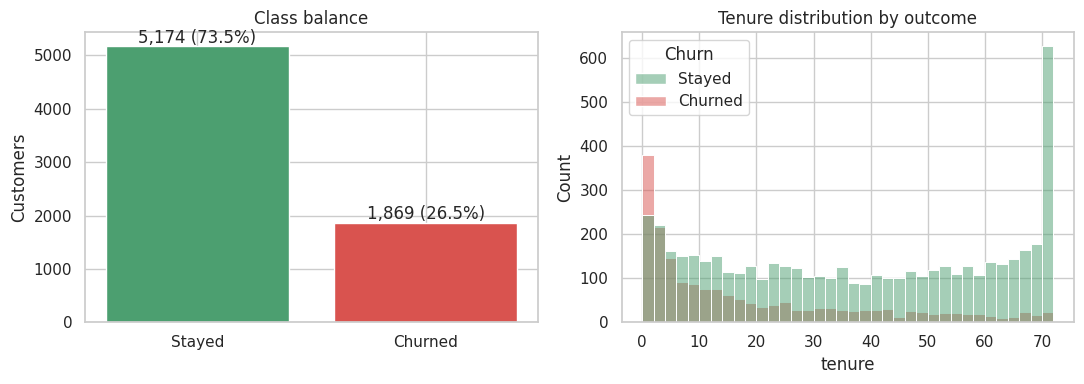

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = df[TARGET].value_counts().sort_index()
axes[0].bar(["Stayed", "Churned"], counts.values, color=["#4C9F70", "#D9534F"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 60, f"{v:,} ({v/len(df):.1%})", ha="center")
axes[0].set_title("Class balance"); axes[0].set_ylabel("Customers")

sns.histplot(data=df, x="tenure", hue=df[TARGET].map({0: "Stayed", 1: "Churned"}),
             bins=36, multiple="layer", palette=["#4C9F70", "#D9534F"], ax=axes[1])
axes[1].set_title("Tenure distribution by outcome")
savefig("01_class_balance_tenure")

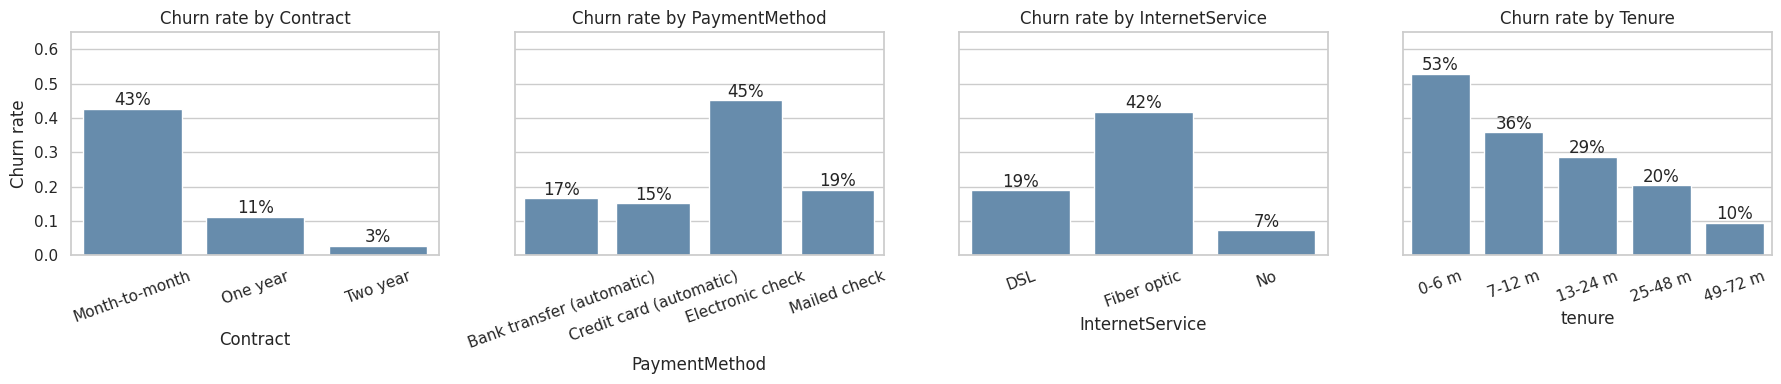

In [5]:
tenure_bucket = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                       labels=["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])
panels = {"Contract": df["Contract"], "PaymentMethod": df["PaymentMethod"],
          "InternetService": df["InternetService"], "Tenure": tenure_bucket}

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, col) in zip(axes, panels.items()):
    rate = df.groupby(col, observed=True)[TARGET].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#5B8DB8")
    for i, v in enumerate(rate.values):
        ax.text(i, v + .01, f"{v:.0%}", ha="center")
    ax.set_title(f"Churn rate by {name}"); ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Churn rate"); axes[0].set_ylim(0, 0.65)
savefig("02_churn_rate_by_segment")

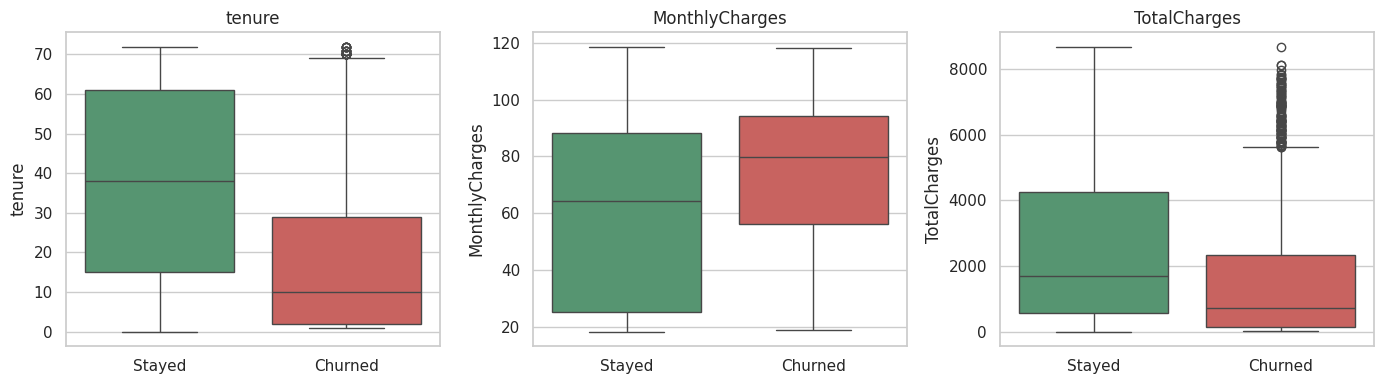

         tenure  MonthlyCharges  TotalCharges
Churn                                        
Stayed     38.0            64.4        1679.5
Churned    10.0            79.6         703.6

corr(TotalCharges, tenure x MonthlyCharges) = 0.9996


In [6]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x=df[TARGET].map({0: "Stayed", 1: "Churned"}), y=c, ax=ax,
                palette=["#4C9F70", "#D9534F"], hue=df[TARGET].map({0: "Stayed", 1: "Churned"}), legend=False)
    ax.set_xlabel(""); ax.set_title(c)
savefig("03_numeric_by_churn")

print(df.groupby(TARGET)[num_cols].median().round(1).rename(index={0: "Stayed", 1: "Churned"}))

# Redundancy check: TotalCharges is almost exactly tenure x MonthlyCharges
r = np.corrcoef(df["TotalCharges"], df["tenure"] * df["MonthlyCharges"])[0, 1]
print(f"\ncorr(TotalCharges, tenure x MonthlyCharges) = {r:.4f}")

**EDA takeaways (verified against the numbers above, not assumed)**

- Churn is **~27%**: imbalanced, so plain accuracy is misleading (a model that always says "stays" scores ~73%).
- Risk is concentrated in **new customers** (churn falls steadily with tenure), **month-to-month contracts**, **fiber-optic internet** and **electronic-check payers**.
- Churners have lower tenure, higher monthly charges and, *because they left early*, lower total charges.
- **`TotalCharges` is essentially `tenure × MonthlyCharges` (corr ≈ 0.9996).** It is nearly redundant, which matters for interpreting coefficients later.

## 4. Train / test split — and lock the test set

The split happens **before** any modelling. From here until Section 9 the test set is untouched: every model choice (algorithm, hyper-parameters, calibration, decision threshold) is made with **cross-validation on the training set only**. Using the test score to pick the winner would make the final number optimistic.

In [7]:
X, y = split_xy(df)                      # drops customerID and the target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
print(f"Train: {X_train.shape} | churn rate {y_train.mean():.3f}")
print(f"Test : {X_test.shape} | churn rate {y_test.mean():.3f}   <- locked until Section 9")

Train: (5634, 19) | churn rate 0.265
Test : (1409, 19) | churn rate 0.265   <- locked until Section 9


## 5. Cross-validated comparison of baseline models

Preprocessing (scaling + one-hot encoding) lives **inside** each pipeline (`src/features.py`), so it is re-fitted on the training part of every fold: no leakage.

We rank models with **threshold-independent** metrics: **ROC-AUC** and **PR-AUC** (average precision, more informative when the positive class is rare). F1/recall/precision at the default 0.5 threshold are shown for reference only; Section 8 chooses the threshold properly.

In [8]:
scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
           "F1": "f1", "Recall": "recall", "Precision": "precision"}

cv_rows, cv_raw = [], {}
for name, model in candidate_models(SEED).items():
    res = cross_validate(make_pipeline(model, X_train), X_train, y_train, cv=cv, scoring=scoring)
    cv_raw[name] = res
    row = {"Model": name}
    for metric in scoring:
        row[metric] = f"{res['test_' + metric].mean():.3f} ± {res['test_' + metric].std():.3f}"
    cv_rows.append(row)

print(f"{N_SPLITS}-fold stratified CV on the training set (mean ± std across folds)")
pd.DataFrame(cv_rows).set_index("Model")

5-fold stratified CV on the training set (mean ± std across folds)


,ROC-AUC,PR-AUC,F1,Recall,Precision
Model,,,,,
Baseline,0.500 ± 0.000,0.265 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic Regression,0.846 ± 0.012,0.660 ± 0.019,0.628 ± 0.023,0.801 ± 0.038,0.517 ± 0.019
Decision Tree,0.830 ± 0.014,0.614 ± 0.027,0.617 ± 0.011,0.781 ± 0.035,0.511 ± 0.011
Random Forest,0.848 ± 0.009,0.662 ± 0.016,0.633 ± 0.016,0.774 ± 0.026,0.536 ± 0.015
LightGBM,0.847 ± 0.012,0.664 ± 0.022,0.632 ± 0.013,0.779 ± 0.021,0.532 ± 0.011


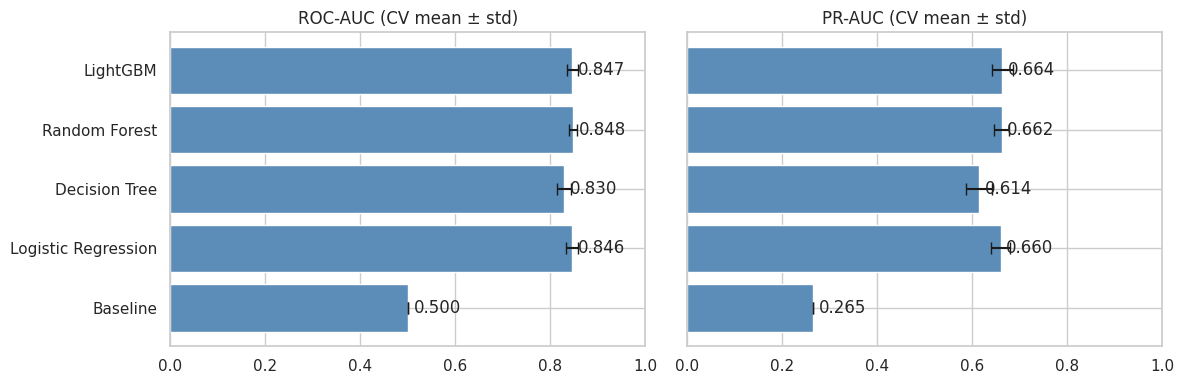

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
names = list(cv_raw)
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    means = [cv_raw[n][f"test_{metric}"].mean() for n in names]
    stds = [cv_raw[n][f"test_{metric}"].std() for n in names]
    ax.barh(names, means, xerr=stds, color="#5B8DB8", capsize=4)
    for i, m in enumerate(means):
        ax.text(m + 0.012, i, f"{m:.3f}", va="center")
    ax.set_title(f"{metric} (CV mean ± std)"); ax.set_xlim(0, 1)
savefig("04_cv_model_comparison")

**Reading this table honestly:** logistic regression, random forest and LightGBM land within noise of each other (ROC-AUC 0.846 to 0.848, with a fold-to-fold std of about 0.01, larger than the gaps between them). The single decision tree is a little weaker (0.830), and every model beats the baseline by a wide margin. On this dataset the **algorithm is not the bottleneck: the information in the features is.** That is why the next steps focus on decisions and explanation rather than chasing a fourth decimal of AUC.

## 6. Does feature engineering help? (ablation)

Feature thinking should be tested, not assumed. Two row-wise features are added (no statistics learned from data, so no leakage): `n_addons` (how many add-on services the customer has) and `is_autopay`. We also test dropping the near-redundant `TotalCharges`.

In [10]:
variants = {
    "Base features": X_train,
    "+ n_addons, is_autopay": add_features(X_train),
    "Base − TotalCharges": X_train.drop(columns=["TotalCharges"]),
}
rows = []
for model_name in ["Logistic Regression", "LightGBM"]:
    for label, Xv in variants.items():
        auc = cross_validate(make_pipeline(candidate_models(SEED)[model_name], Xv), Xv, y_train,
                             cv=cv, scoring="roc_auc")["test_score"]
        rows.append({"Model": model_name, "Feature set": label, "CV ROC-AUC": f"{auc.mean():.4f} ± {auc.std():.4f}"})
pd.DataFrame(rows)

,Model,Feature set,CV ROC-AUC
0,Logistic Regression,Base features,0.8460 ± 0.0124
1,Logistic Regression,"+ n_addons, is_autopay",0.8460 ± 0.0124
2,Logistic Regression,Base − TotalCharges,0.8448 ± 0.0121
3,LightGBM,Base features,0.8468 ± 0.0115
4,LightGBM,"+ n_addons, is_autopay",0.8462 ± 0.0119
5,LightGBM,Base − TotalCharges,0.8441 ± 0.0101


**Result: none of the variants moves AUC beyond noise.** The engineered features are already implied by the raw columns, and dropping the redundant `TotalCharges` costs nothing. Per the roadmap's *"baseline-first"* principle, we keep the simpler base feature set. A negative result like this is still a result: it tells us further gains would need **new information** (usage, complaints, price changes, support calls), not cleverer transformations of the same columns.

## 7. Hyper-parameter tuning and model selection

Each family gets a randomized search with 5-fold CV, optimising ROC-AUC. Then we apply a **one-standard-error rule**: *choose the simplest model whose CV score is within one standard error of the best.* If a logistic regression is statistically tied with LightGBM, we ship the logistic regression: cheaper, faster and explainable.

*(Caveat: the tuned scores below are slightly optimistic because the same folds choose the hyper-parameters and report the score. The untouched test set in Section 9 gives the unbiased number.)*

In [11]:
searches = {}
for name, n_iter in DEFAULT_N_ITER.items():      # same search budget as `python -m src.train`
    s = RandomizedSearchCV(
        make_pipeline(candidate_models(SEED)[name], X_train),
        param_distributions=search_spaces()[name], n_iter=n_iter,
        scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1, refit=True)
    s.fit(X_train, y_train)
    searches[name] = s

summary, rows = {}, []
for name, s in searches.items():
    i = s.best_index_
    mean, std = s.cv_results_["mean_test_score"][i], s.cv_results_["std_test_score"][i]
    summary[name] = (mean, std)
    untuned = cv_raw[name]["test_ROC-AUC"].mean()
    rows.append({"Model": name, "Untuned CV AUC": round(untuned, 4), "Tuned CV AUC": round(mean, 4),
                 "Std (folds)": round(std, 4), "Best params": {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                                                                for k, v in s.best_params_.items()}})
pd.DataFrame(rows).set_index("Model")

,Untuned CV AUC,Tuned CV AUC,Std (folds),Best params
Model,,,,
Logistic Regression,0.8460,0.8462,0.0128,{'C': 14.5282}
Decision Tree,0.8297,0.8308,0.0140,"{'max_depth': 5, 'min_samples_leaf': 46}"
Random Forest,0.8476,0.8481,0.0103,"{'max_depth': 11, 'max_features': 'sqrt', 'min..."
LightGBM,0.8468,0.8500,0.0123,"{'colsample_bytree': 0.5035, 'learning_rate': ..."


In [12]:
chosen = one_standard_error_choice(summary, N_SPLITS)
best_name = max(summary, key=lambda k: summary[k][0])
se = summary[best_name][1] / np.sqrt(N_SPLITS)
print(f"Highest CV AUC : {best_name} ({summary[best_name][0]:.4f})")
print(f"1-SE threshold : {summary[best_name][0] - se:.4f}")
print(f"Selected model : {chosen} ({summary[chosen][0]:.4f})  <- simplest model within 1 SE of the best")

Highest CV AUC : LightGBM (0.8500)
1-SE threshold : 0.8445
Selected model : Logistic Regression (0.8462)  <- simplest model within 1 SE of the best


## 8. Calibration and the profit-optimal threshold

**Why calibrate?** We trained with `class_weight='balanced'`, which makes the model treat churners as more important, and as a side effect **inflates predicted probabilities**. A score of 0.6 then does *not* mean "60% chance of churn", and any expected-value calculation built on it would be wrong. `CalibratedClassifierCV` (Platt scaling) maps scores back to honest probabilities.

All curves here use **out-of-fold predictions on the training set**: each customer is scored by a model that never saw them, and the test set stays locked.

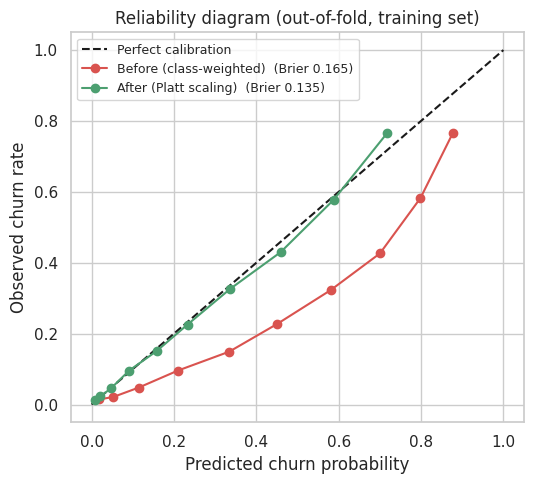

Mean predicted risk  before: 0.414 | after: 0.266 | actual churn rate: 0.265


In [13]:
chosen_pipe = clone(searches[chosen].best_estimator_)                 # unfitted, tuned
calibrated = CalibratedClassifierCV(chosen_pipe, method="sigmoid", cv=5)

oof_raw = cross_val_predict(chosen_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_cal = cross_val_predict(calibrated,  X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for label, p, c in [("Before (class-weighted)", oof_raw, "#D9534F"), ("After (Platt scaling)", oof_cal, "#4C9F70")]:
    frac_pos, mean_pred = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", color=c, label=f"{label}  (Brier {brier_score_loss(y_train, p):.3f})")
ax.set_xlabel("Predicted churn probability"); ax.set_ylabel("Observed churn rate")
ax.set_title("Reliability diagram (out-of-fold, training set)"); ax.legend(loc="upper left", fontsize=9)
savefig("05_calibration")
print(f"Mean predicted risk  before: {oof_raw.mean():.3f} | after: {oof_cal.mean():.3f} | actual churn rate: {y_train.mean():.3f}")

### From probability to decision: the economics

The campaign economics below are **assumptions to be replaced with real finance numbers** (they are cheap to change: edit one line):

| Assumption | Value | Meaning |
|---|---|---|
| Contact cost | ₹500 | Cost of one retention offer, paid for *every* customer contacted |
| Customer value | ₹5,000 | Value of keeping a customer who would have left |
| Save rate | 30% | Share of would-be churners the offer actually retains |

Contacting customer *i* has expected profit `0.30 × 5000 × P(churn) − 500`, which is positive only when **P(churn) > 500 / (0.30 × 5000) = 0.33**. That closed-form threshold is a sanity check for the empirical optimum found from the data.

*Note: the ₹ figures are illustrative campaign-economics assumptions, not derived from the dataset (whose own charge columns are in the dataset's native currency).*

Theoretical break-even probability : 0.33
Empirical profit-optimal threshold : 0.36  (chosen on training out-of-fold predictions)
Thresholds within 3% of max profit : 0.30 - 0.39  -> a broad, forgiving plateau


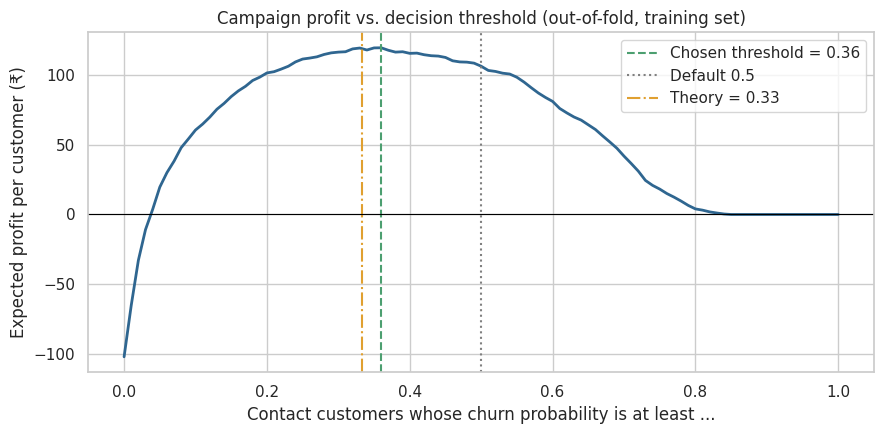

In [14]:
econ = RetentionEconomics(contact_cost=500, customer_value=5000, success_rate=0.30)

curve = profit_curve(y_train, oof_cal, econ)
THRESHOLD = best_threshold(y_train, oof_cal, econ)
max_profit = curve["profit"].max()
near_opt = curve[curve["profit"] >= 0.97 * max_profit]["threshold"]

print(f"Theoretical break-even probability : {econ.breakeven_probability:.2f}")
print(f"Empirical profit-optimal threshold : {THRESHOLD:.2f}  (chosen on training out-of-fold predictions)")
print(f"Thresholds within 3% of max profit : {near_opt.min():.2f} - {near_opt.max():.2f}  -> a broad, forgiving plateau")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve["threshold"], curve["profit"] / len(y_train), color="#2F6690", lw=2)
ax.axvline(THRESHOLD, color="#4C9F70", ls="--", label=f"Chosen threshold = {THRESHOLD:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="Default 0.5")
ax.axvline(econ.breakeven_probability, color="#E0A030", ls="-.", label=f"Theory = {econ.breakeven_probability:.2f}")
ax.axhline(0, color="black", lw=.8)
ax.set_xlabel("Contact customers whose churn probability is at least ..."); ax.set_ylabel("Expected profit per customer (₹)")
ax.set_title("Campaign profit vs. decision threshold (out-of-fold, training set)"); ax.legend()
savefig("06_profit_vs_threshold")

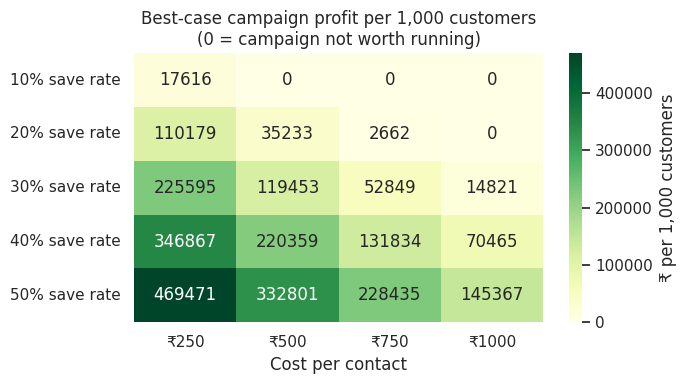

In [15]:
# Sensitivity: how robust is the campaign to the assumptions?
success_rates = [0.10, 0.20, 0.30, 0.40, 0.50]
costs = [250, 500, 750, 1000]
grid = pd.DataFrame(index=[f"{int(s*100)}% save rate" for s in success_rates],
                    columns=[f"₹{c}" for c in costs], dtype=float)
for s in success_rates:
    for c in costs:
        e = RetentionEconomics(contact_cost=c, customer_value=5000, success_rate=s)
        t = best_threshold(y_train, oof_cal, e)
        grid.loc[f"{int(s*100)}% save rate", f"₹{c}"] = max(0, campaign_profit(y_train, oof_cal, t, e)) / len(y_train) * 1000

plt.figure(figsize=(7, 4))
sns.heatmap(grid, annot=True, fmt=".0f", cmap="YlGn", cbar_kws={"label": "₹ per 1,000 customers"})
plt.title("Best-case campaign profit per 1,000 customers\n(0 = campaign not worth running)")
plt.xlabel("Cost per contact")
savefig("07_profit_sensitivity")

**Takeaways.** The optimum sits on a wide plateau, so the exact threshold is not delicate. The decision *does* depend heavily on the save rate: when offers rarely work, or are expensive relative to customer value, the right answer shrinks toward "contact almost nobody". **The first real-world action is therefore to measure the save rate with a small A/B test before scaling the campaign.**

## 9. Final one-shot evaluation on the locked test set

Everything is now fixed: model family, hyper-parameters, calibration and threshold. We fit on the full training set and score the test set **once**.

Selected model : Logistic Regression (tuned, calibrated)
Test ROC-AUC   : 0.841   95% CI [0.817, 0.861]
Test PR-AUC    : 0.627   95% CI [0.575, 0.679]   (baseline = churn rate 0.265)
Test Brier     : 0.139


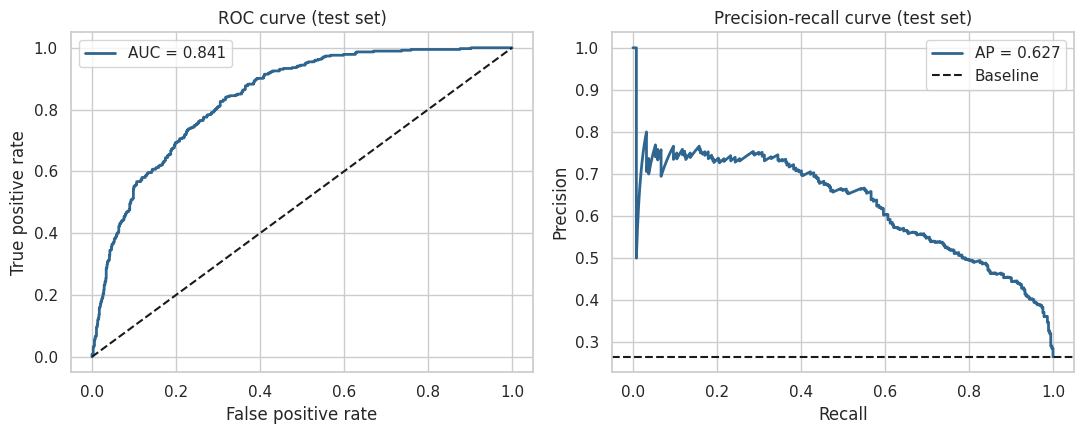

In [16]:
final_model = clone(calibrated).fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]

def boot_ci(metric, y_true, p, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, p = np.asarray(y_true), np.asarray(p)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        vals.append(metric(y_true[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

auc, ap = roc_auc_score(y_test, p_test), average_precision_score(y_test, p_test)
auc_lo, auc_hi = boot_ci(roc_auc_score, y_test, p_test)
ap_lo, ap_hi = boot_ci(average_precision_score, y_test, p_test)
print(f"Selected model : {chosen} (tuned, calibrated)")
print(f"Test ROC-AUC   : {auc:.3f}   95% CI [{auc_lo:.3f}, {auc_hi:.3f}]")
print(f"Test PR-AUC    : {ap:.3f}   95% CI [{ap_lo:.3f}, {ap_hi:.3f}]   (baseline = churn rate {y_test.mean():.3f})")
print(f"Test Brier     : {brier_score_loss(y_test, p_test):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color="#2F6690", lw=2, label=f"AUC = {auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (test set)"); axes[0].legend()
prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rec, prec, color="#2F6690", lw=2, label=f"AP = {ap:.3f}")
axes[1].axhline(y_test.mean(), color="k", ls="--", label="Baseline")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve (test set)"); axes[1].legend()
savefig("08_test_roc_pr")

                Threshold  Precision  Recall     F1  Contacted   TP   FP   FN
Default 0.5          0.50      0.659   0.553  0.602        314  207  107  167
Profit-optimal       0.36      0.547   0.706  0.616        483  264  219  110


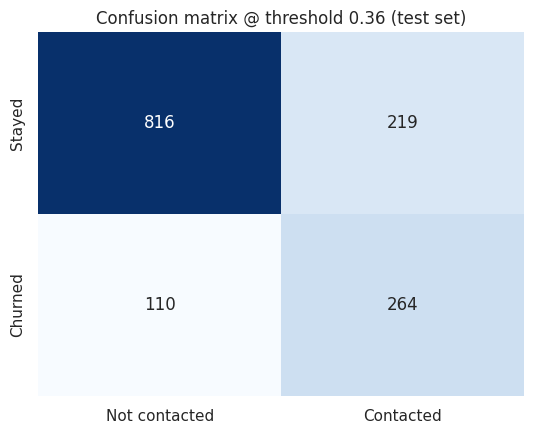

In [17]:
def metrics_at(t):
    pred = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Threshold": round(t, 2), "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred), "Contacted": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn}

print(pd.DataFrame([metrics_at(0.5), metrics_at(THRESHOLD)], index=["Default 0.5", "Profit-optimal"]).round(3).to_string())

pred_final = (p_test >= THRESHOLD).astype(int)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y_test, pred_final), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Not contacted", "Contacted"], yticklabels=["Stayed", "Churned"])
plt.title(f"Confusion matrix @ threshold {THRESHOLD:.2f} (test set)")
savefig("09_confusion_matrix")

### What is the campaign worth? Strategy comparison on the test set

In [18]:
n = len(y_test)
churners = int(y_test.sum())
order = np.argsort(-p_test)
top20 = np.zeros(n, dtype=int); top20[order[: int(0.2 * n)]] = 1

def evaluate(contact_flags):
    contact_flags = np.asarray(contact_flags).astype(bool)
    gain = np.asarray(y_test) * econ.success_rate * econ.customer_value - econ.contact_cost
    profit = float((contact_flags * gain).sum())
    caught = int((contact_flags & (np.asarray(y_test) == 1)).sum())
    return {"Customers contacted": int(contact_flags.sum()), "Churners reached": caught,
            "Share of churners reached": caught / churners, "Expected profit (₹)": profit,
            "Profit per customer (₹)": profit / n}

strategies = {
    "Contact nobody": np.zeros(n),
    "Contact everybody": np.ones(n),
    "Model @ 0.5": (p_test >= 0.5),
    f"Model @ {THRESHOLD:.2f} (profit-optimal)": (p_test >= THRESHOLD),
    "Model: top 20% by risk (fixed budget)": top20,
    "Oracle (knows who churns; upper bound)": np.asarray(y_test),
}
results = pd.DataFrame({k: evaluate(v) for k, v in strategies.items()}).T
results["Share of churners reached"] = (results["Share of churners reached"] * 100).round(1).astype(str) + "%"
results["Expected profit (₹)"] = results["Expected profit (₹)"].round(0)
results["Profit per customer (₹)"] = results["Profit per customer (₹)"].round(1)
results

,Customers contacted,Churners reached,Share of churners reached,Expected profit (₹),Profit per customer (₹)
Contact nobody,0.0,0.0,0.0%,0.0,0.0
Contact everybody,1409.0,374.0,100.0%,-143500.0,-101.8
Model @ 0.5,314.0,207.0,55.3%,153500.0,108.9
Model @ 0.36 (profit-optimal),483.0,264.0,70.6%,154500.0,109.7
Model: top 20% by risk (fixed budget),281.0,186.0,49.7%,138500.0,98.3
Oracle (knows who churns; upper bound),374.0,374.0,100.0%,374000.0,265.4


Profit uplift of the model-targeted campaign vs. contacting everybody (test set, 1,409 customers):
  point estimate ₹298,000  |  95% bootstrap CI [₹267,975, ₹330,000]


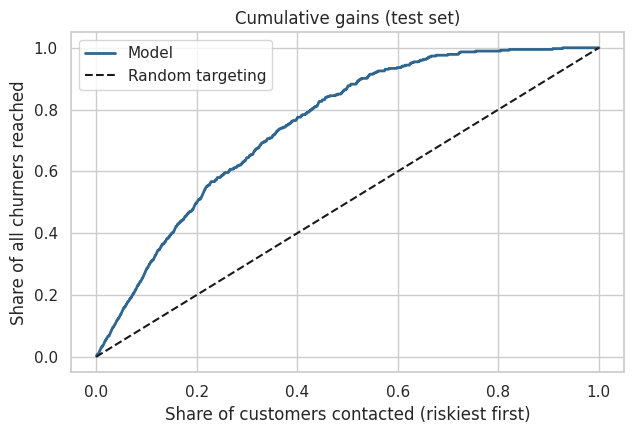

Contacting the top 10% riskiest customers reaches 28% of churners
Contacting the top 20% riskiest customers reaches 50% of churners
Contacting the top 30% riskiest customers reaches 64% of churners


In [19]:
# Bootstrap uncertainty on the profit of the chosen strategy and its uplift vs. contacting everybody
rng = np.random.default_rng(SEED)
yv, pv = np.asarray(y_test), p_test
uplift = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    uplift.append(campaign_profit(yv[idx], pv[idx], THRESHOLD, econ) - campaign_profit(yv[idx], pv[idx], 0.0, econ))
lo, hi = np.percentile(uplift, [2.5, 97.5])
print(f"Profit uplift of the model-targeted campaign vs. contacting everybody (test set, {n:,} customers):")
print(f"  point estimate ₹{campaign_profit(yv, pv, THRESHOLD, econ) - campaign_profit(yv, pv, 0.0, econ):,.0f}  |  95% bootstrap CI [₹{lo:,.0f}, ₹{hi:,.0f}]")

# Gains chart: what share of churners do we reach by contacting the top X% riskiest customers?
sorted_y = np.asarray(y_test)[order]
cum_caught = np.cumsum(sorted_y) / sorted_y.sum()
x = np.arange(1, n + 1) / n
plt.figure(figsize=(6.5, 4.5))
plt.plot(x, cum_caught, color="#2F6690", lw=2, label="Model")
plt.plot([0, 1], [0, 1], "k--", label="Random targeting")
plt.xlabel("Share of customers contacted (riskiest first)"); plt.ylabel("Share of all churners reached")
plt.title("Cumulative gains (test set)"); plt.legend()
savefig("10_gains_chart")
for pct in (0.1, 0.2, 0.3):
    print(f"Contacting the top {int(pct*100)}% riskiest customers reaches {cum_caught[int(pct*n)-1]:.0%} of churners")

**Reading the comparison** *(numbers from the seeded run, random_state=42)*

- **Contacting everybody loses money** (about −₹102 per customer): ~73% of the offers go to people who would have stayed. Model-targeted contact turns the same campaign into roughly **+₹110 per customer**.
- **The profit-optimal threshold (0.36) and the default 0.5 earn almost the same profit** (≈₹154.5k vs ≈₹153.5k across 1,409 test customers). That is the plateau from Section 8 showing up on unseen data: the threshold is not fragile. What changes is *who* you reach: **0.36 reaches 71% of churners vs 55% at 0.5**, at the cost of more false alarms. If a missed churner hurts more than a wasted offer, prefer the lower threshold.
- **A fixed 20% outreach budget** reaches about half of all churners, a 2.5× improvement over random targeting.
- **The oracle bound** (knowing exactly who will churn) is ≈₹265 per customer, so the model captures roughly **41% of the achievable profit**. The remaining gap is the price of imperfect information (see error analysis).

## 10. Explaining the model

Two complementary views:
1. **Logistic-regression coefficients**: a global, directly readable model (the "challenger" we could ship if it is selected).
2. **SHAP on the tuned LightGBM**: both global importance and a *per-customer* explanation of why someone is flagged.

*(Caveat for coefficients: features like `OnlineSecurity_No internet service`, `StreamingTV_No internet service`, and `InternetService_No` are duplicates of one another, and `TotalCharges` ≈ `tenure × MonthlyCharges`. With regularisation, credit gets split between redundant columns, so read **groups of related coefficients together**, not any single one.)*

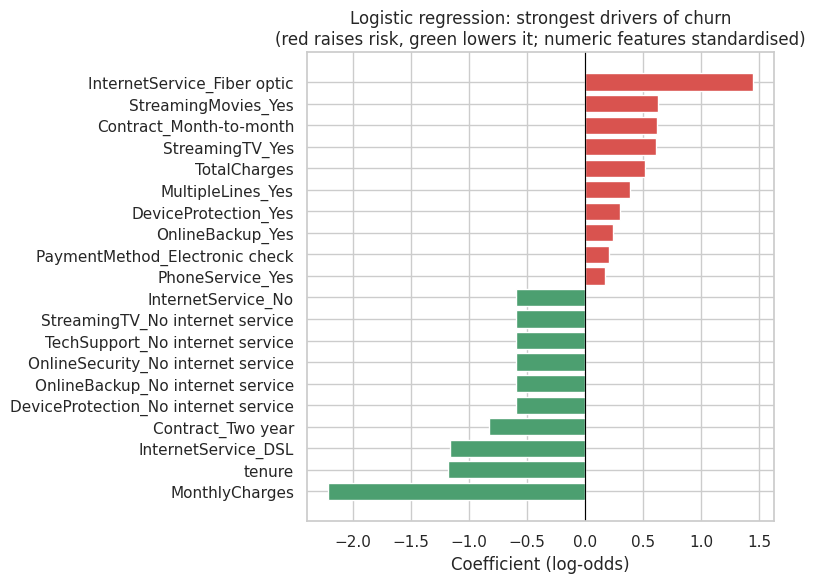

In [20]:
lr_best = searches["Logistic Regression"].best_estimator_
names = lr_best.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_best.named_steps["model"].coef_[0], index=[n.split("__", 1)[1] for n in names]).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["#4C9F70" if v < 0 else "#D9534F" for v in top.values])
plt.axvline(0, color="black", lw=.8)
plt.title("Logistic regression: strongest drivers of churn\n(red raises risk, green lowers it; numeric features standardised)")
plt.xlabel("Coefficient (log-odds)")
savefig("11_lr_coefficients")

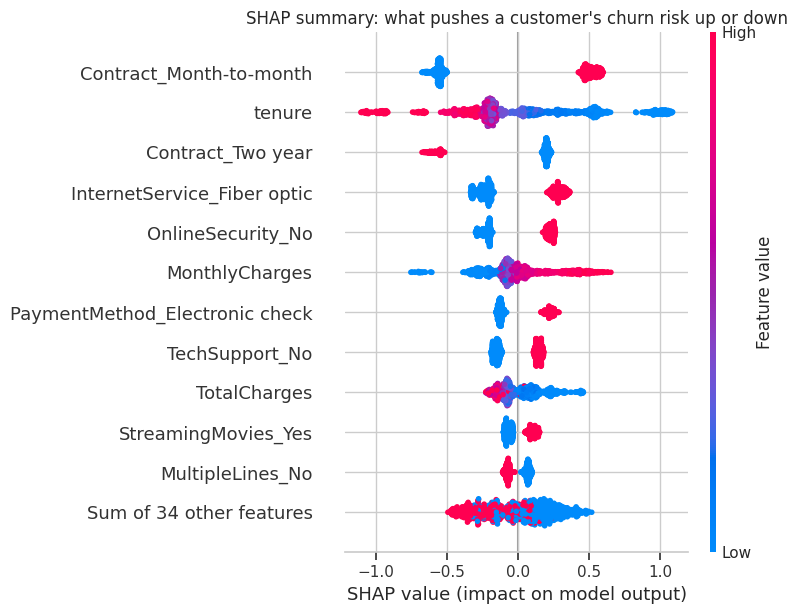

In [21]:
import shap

lgbm_best = searches["LightGBM"].best_estimator_
prep, lgbm = lgbm_best.named_steps["prep"], lgbm_best.named_steps["model"]
feat_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
Xt_test = pd.DataFrame(prep.transform(X_test), columns=feat_names, index=X_test.index)

explainer = shap.TreeExplainer(lgbm)
sv = explainer(Xt_test)
if sv.values.ndim == 3:            # some shap versions return one slice per class
    sv = sv[:, :, 1]

# Show original (un-standardised) values in the plots, e.g. tenure = 1 month rather than -1.28
display_data = Xt_test.copy()
for c in X_test.select_dtypes(include="number").columns:
    display_data[c] = X_test[c].values
sv.data = display_data.values

shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP summary: what pushes a customer's churn risk up or down")
savefig("12_shap_summary")

Highest-risk test customer: predicted churn probability 84%, actual outcome: churned


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
value,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.1,95.1


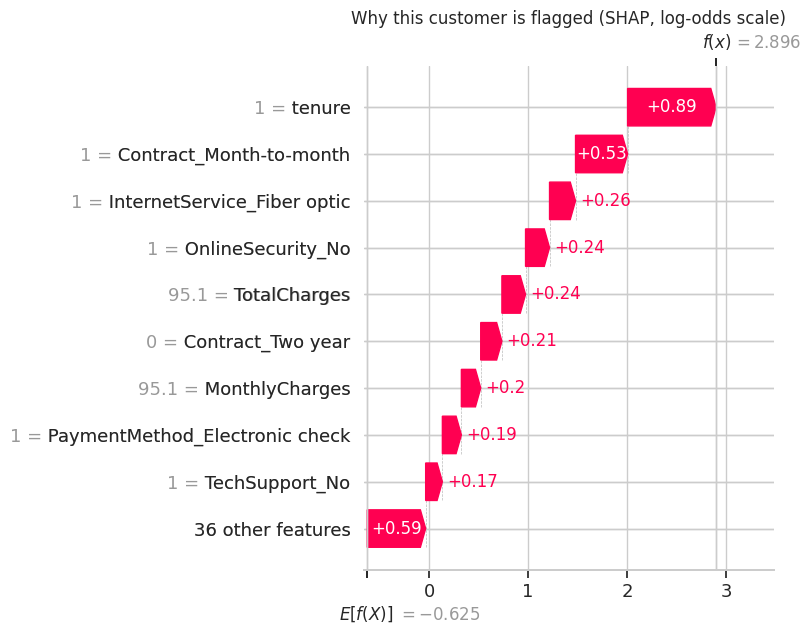

In [22]:
# Why was *this* customer flagged? Explain the single highest-risk customer in the test set.
i = int(np.argmax(p_test))
print(f"Highest-risk test customer: predicted churn probability {p_test[i]:.0%}, actual outcome: {'churned' if y_test.iloc[i] else 'stayed'}")
display(X_test.iloc[[i]].T.rename(columns={X_test.index[i]: "value"}).T)

shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.title("Why this customer is flagged (SHAP, log-odds scale)")
savefig("13_shap_waterfall")

**Business readout.** Both views agree on the same story: **contract type and tenure dominate**, followed by **missing protective add-ons (online security, tech support)**, **fiber-optic service**, **electronic-check payment** and **high monthly charges**. Practical levers for the retention team: move month-to-month customers onto longer contracts, bundle security/tech-support for new fiber customers, and nudge electronic-check payers toward autopay.

*Caution: these are associations, not proven causes. "Customers without tech support churn more" does not mean giving tech support to everyone will reduce churn. That is what an A/B test is for.*

## 11. Error analysis: where does the model fail, and why?

We use the final model at the profit-optimal threshold on the test set and ask three questions: **who do we miss** (false negatives), **who do we wrongly flag** (false positives), and **are errors concentrated in particular segments?**

In [23]:
ea = X_test.copy()
ea["actual"] = y_test.values
ea["proba"] = p_test
ea["pred"] = (p_test >= THRESHOLD).astype(int)
ea["outcome"] = np.select(
    [(ea.actual == 1) & (ea.pred == 1), (ea.actual == 1) & (ea.pred == 0),
     (ea.actual == 0) & (ea.pred == 1)], ["TP (caught churner)", "FN (missed churner)", "FP (false alarm)"],
    default="TN (correctly left alone)")
ea = add_features(ea)  # adds n_addons for profiling only
ea["tenure_bucket"] = pd.cut(ea["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])

print(ea["outcome"].value_counts().to_string())

profile = ea.groupby("outcome").agg(
    n=("actual", "size"), mean_proba=("proba", "mean"), tenure=("tenure", "mean"),
    monthly_charges=("MonthlyCharges", "mean"), n_addons=("n_addons", "mean"),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean()),
    pct_electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean()),
).round(2)
profile

outcome
TN (correctly left alone)    816
TP (caught churner)          264
FP (false alarm)             219
FN (missed churner)          110


,n,mean_proba,tenure,monthly_charges,n_addons,pct_month_to_month,pct_fiber,pct_electronic_check
outcome,,,,,,,,
FN (missed churner),110,0.20,28.05,62.34,2.11,0.63,0.34,0.28
FP (false alarm),219,0.53,18.68,78.52,1.77,0.97,0.78,0.60
TN (correctly left alone),816,0.10,42.55,56.24,2.15,0.28,0.23,0.17
TP (caught churner),264,0.60,11.63,77.11,1.46,0.98,0.81,0.66


In [24]:
def segment_report(col):
    g = ea.groupby(col, observed=True)
    rep = pd.DataFrame({
        "customers": g.size(),
        "churn_rate": g["actual"].mean(),
        "recall": g.apply(lambda d: recall_score(d.actual, d.pred) if d.actual.sum() else np.nan),
        "precision": g.apply(lambda d: precision_score(d.actual, d.pred, zero_division=0)),
        "missed_churners": g.apply(lambda d: int(((d.actual == 1) & (d.pred == 0)).sum())),
    })
    return rep.round(2)

for col in ["tenure_bucket", "Contract", "InternetService"]:
    print(f"\n--- by {col} ---")
    print(segment_report(col).to_string())


--- by tenure_bucket ---
               customers  churn_rate  recall  precision  missed_churners
tenure_bucket                                                           
0-6 m                311        0.56    0.80       0.68               35
7-12 m               138        0.30    0.71       0.45               12
13-24 m              206        0.29    0.85       0.47                9
25-48 m              304        0.21    0.62       0.48               24
49-72 m              450        0.08    0.14       0.23               30

--- by Contract ---
                customers  churn_rate  recall  precision  missed_churners
Contract                                                                 
Month-to-month        773        0.43    0.79       0.55               69
One year              300        0.12    0.11       0.36               32
Two year              336        0.03    0.00       0.00                9

--- by InternetService ---
                 customers  churn_rate  reca

In [25]:
cols = ["tenure", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges", "n_addons", "proba"]
print("Deepest misses: churners the model was most confident would STAY")
display(ea[ea.actual == 1].nsmallest(6, "proba")[cols].round(2))
print("Loudest false alarms: customers flagged as very likely to churn who actually stayed")
display(ea[ea.actual == 0].nlargest(6, "proba")[cols].round(2))

Deepest misses: churners the model was most confident would STAY


,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,n_addons,proba
4386,55,Two year,DSL,Bank transfer (automatic),57.55,3,0.01
4513,72,Two year,DSL,Credit card (automatic),92.45,6,0.01
2894,48,One year,DSL,Credit card (automatic),60.35,3,0.03
5086,45,One year,No,Electronic check,20.40,0,0.03
3834,57,One year,DSL,Bank transfer (automatic),70.10,3,0.04
3694,67,Two year,Fiber optic,Credit card (automatic),108.75,5,0.05


Loudest false alarms: customers flagged as very likely to churn who actually stayed


,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,n_addons,proba
3346,2,Month-to-month,Fiber optic,Electronic check,84.05,1,0.81
935,4,Month-to-month,Fiber optic,Electronic check,83.25,1,0.81
4039,7,Month-to-month,Fiber optic,Electronic check,94.10,2,0.80
352,7,Month-to-month,Fiber optic,Electronic check,89.15,2,0.78
5019,14,Month-to-month,Fiber optic,Electronic check,95.60,2,0.78
2350,5,Month-to-month,Fiber optic,Electronic check,84.00,1,0.77


**What the error analysis shows** *(numbers from the seeded run, random_state=42)*

1. **False alarms are "textbook-risk" customers who happened to stay.** The 219 false positives look almost identical to the 264 caught churners: ~97% month-to-month, ~78% fiber, ~60% electronic check, short tenure. Within this high-risk profile, nothing in the data separates stayers from leavers, so these errors are probably irreducible with the current features. Their cost is a wasted offer, not a lost customer.
2. **Misses are concentrated among loyal, long-contract customers.** Recall is only **14%** for customers with 49 to 72 months of tenure, **11%** on one-year contracts, and **0%** on two-year contracts and for customers without internet. The model gives these groups very low probabilities, rationally, because their base churn rates are only 3 to 12%. Of the 110 missed churners, **41 (37%) are on one- or two-year contracts** and 30 have 4+ years of tenure. The deepest miss is a 72-month, two-year-contract, auto-pay customer scored at 1% churn risk: nothing in this dataset warns about them.
3. **Where it works best:** new customers (0 to 6 months: recall 80%) and month-to-month (79%) or fiber-optic (85%) customers, exactly the group where most churn happens.

**Implication.** The model is a good *early-warning system for new and month-to-month customers* and a poor detector of *sudden departures among loyal customers*. Catching those would take information this dataset does not contain: recent complaints, support calls, usage drops, price changes, competitor offers. **Collecting that data would be worth more than any further tuning.**

## 12. Customer segmentation (K-Means)

Supervised models say *who is at risk*; clustering says *what kinds of customers we have*. We cluster on **tenure, monthly charges, number of add-on services and contract length**. The churn label is **not** used to form the clusters; it is only used afterwards to profile them, so there is no leakage.

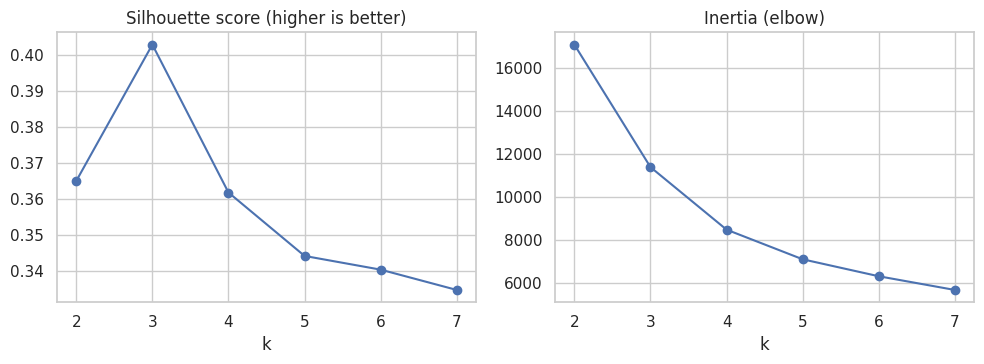

Silhouette by k: {2: 0.365, 3: 0.403, 4: 0.362, 5: 0.344, 6: 0.34, 7: 0.335} -> using k = 3


In [26]:
seg = pd.DataFrame({
    "tenure": df["tenure"], "MonthlyCharges": df["MonthlyCharges"],
    "n_addons": (df[ADDON_COLS] == "Yes").sum(axis=1),
    "contract_length": df["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2}),
})
Z = StandardScaler().fit_transform(seg)

ks = range(2, 8)
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)) for k in ks}
inertia = {k: KMeans(k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in ks}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(list(ks), list(sil.values()), "o-"); axes[0].set_title("Silhouette score (higher is better)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), list(inertia.values()), "o-"); axes[1].set_title("Inertia (elbow)"); axes[1].set_xlabel("k")
savefig("14_kmeans_k_selection")

K = max(range(3, 7), key=lambda k: sil[k])      # at least 3 segments, at most 6, so they stay explainable
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> using k =", K)

In [27]:
df_seg = df.copy()
df_seg["segment"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(Z)
df_seg["n_addons"] = seg["n_addons"]

profile = df_seg.groupby("segment").agg(
    customers=("segment", "size"),
    tenure=("tenure", "mean"), monthly_charges=("MonthlyCharges", "mean"), n_addons=("n_addons", "mean"),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean()),
    churn_rate=(TARGET, "mean"),
)
profile["share_of_all_churners"] = df_seg.groupby("segment")[TARGET].sum() / df_seg[TARGET].sum()
profile["share_of_customers"] = profile["customers"] / len(df_seg)
profile = profile.sort_values("churn_rate", ascending=False).round(2)
profile

,customers,tenure,monthly_charges,n_addons,pct_month_to_month,pct_fiber,churn_rate,share_of_all_churners,share_of_customers
segment,,,,,,,,,
2,3646,14.62,63.00,1.34,0.95,0.50,0.42,0.83,0.52
0,2232,56.32,88.65,4.12,0.18,0.57,0.13,0.16,0.32
1,1165,42.03,24.50,0.23,0.01,0.00,0.02,0.01,0.17


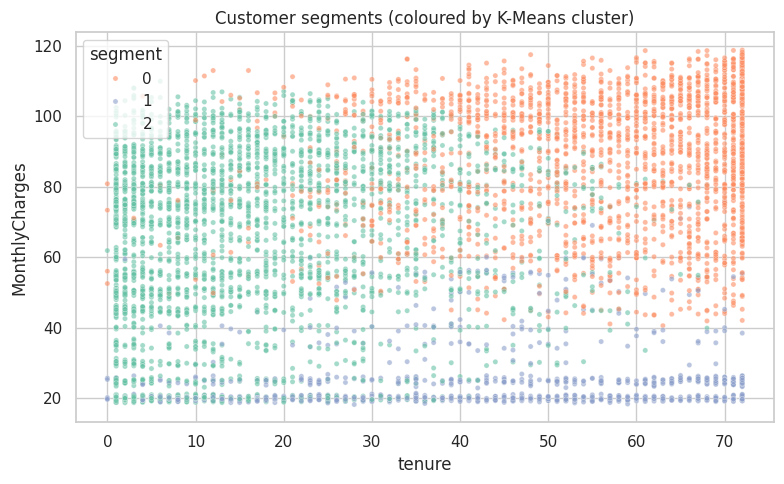

In [28]:
order_by_risk = profile.index.tolist()
palette = dict(zip(order_by_risk, sns.color_palette("Set2", K)))
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_seg, x="tenure", y="MonthlyCharges", hue="segment", palette=palette, s=14, alpha=.6)
plt.title("Customer segments (coloured by K-Means cluster)")
savefig("15_segments_scatter")

## 13. Save the model and verify the saved artifact

In [29]:
metrics = {
    "model": chosen, "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "cv_roc_auc_tuned": {k: round(v[0], 4) for k, v in summary.items()},
    "test_roc_auc": round(auc, 4), "test_roc_auc_ci95": [round(auc_lo, 4), round(auc_hi, 4)],
    "test_pr_auc": round(ap, 4), "test_brier": round(brier_score_loss(y_test, p_test), 4),
    "threshold": round(THRESHOLD, 3), "economics_assumptions": asdict(econ),
    "test_recall_at_threshold": round(recall_score(y_test, pred_final), 4),
    "test_precision_at_threshold": round(precision_score(y_test, pred_final), 4),
}
bundle = {"model": final_model, "threshold": float(THRESHOLD), "features": list(X_train.columns),
          "economics": asdict(econ), "metrics": metrics}

(PROJECT_ROOT / "models").mkdir(exist_ok=True)
joblib.dump(bundle, PROJECT_ROOT / "models" / "churn_model.joblib")
(PROJECT_ROOT / "reports" / "metrics.json").write_text(json.dumps(metrics, indent=2))

# Reload and verify the artifact reproduces the notebook's predictions exactly
from src.predict import load_bundle, score
reloaded = load_bundle()
scored = score(X_test, reloaded)
assert np.allclose(scored["churn_probability"].values, p_test), "Saved model disagrees with notebook!"
print("Saved models/churn_model.joblib and reports/metrics.json; reloaded model reproduces test predictions exactly.\n")
scored.assign(actual=y_test).sort_values("churn_probability", ascending=False).head(8).round(3)

Saved models/churn_model.joblib and reports/metrics.json; reloaded model reproduces test predictions exactly.



,churn_probability,contact,risk_tier,actual
3380,0.840,True,High,1
2631,0.820,True,High,1
6866,0.813,True,High,1
3346,0.810,True,High,0
935,0.807,True,High,0
4039,0.805,True,High,0
4585,0.803,True,High,1
2397,0.799,True,High,1


**Three segments emerge** *(read the table above; numbers from the seeded run)*

| Segment | Profile | Business play |
|---|---|---|
| **New month-to-month customers** | ~52% of customers, **~83% of all churners**, churn ≈ 42%, tenure ≈ 15 months, 95% month-to-month | The retention campaign belongs here. The churn model ranks customers *within* this group |
| **Loyal premium customers** | ~32% of customers, tenure ≈ 56 months, highest monthly charges, ~4 add-on services, churn ≈ 13% | Few leave, but each is valuable and the churn model misses most of them (Section 11): protect with account management and loyalty offers |
| **Low-spend phone-only customers** | ~17% of customers, no internet service, lowest charges, churn ≈ 2% | Leave alone: contacting them only costs money |

Silhouette is highest at k = 3, so the clusters are coarse but cleanly interpretable. The point is the contrast: more than 4 in 5 churners sit in a single segment that is just over half the customer base.

## 14. Summary

**Result.** A tuned, calibrated **logistic regression** was selected by cross-validation using a one-standard-error rule: LightGBM scored marginally higher in CV, but the difference was within noise, so the simpler, explainable model wins.

| Metric (locked test set, 1,409 customers) | Value |
|---|---|
| ROC-AUC | **0.841** (95% CI 0.817 to 0.861) |
| PR-AUC | **0.627** (baseline 0.265) |
| Recall / precision at the profit-optimal threshold (0.36) | **71% / 55%** |
| Expected campaign profit | **≈ +₹110 per customer** vs ≈ −₹102 for contacting everybody |

**Decisions made along the way, and why**

- Test set locked; all selection by cross-validation → unbiased final score.
- Engineered features tested and *rejected* (no gain) → simpler model.
- Probability calibration → trustworthy expected-value maths.
- Threshold chosen from economics, not from habit (0.5).
- The model is explainable (coefficients and SHAP) and its failure modes are documented.

**Limitations (be upfront about these)**

- **Snapshot data, no time dimension.** A real deployment needs out-of-time validation (train on earlier months, test on later ones) and drift monitoring.
- **Economics are assumptions.** The save rate in particular is unknown. Section 8 shows it is the assumption that matters most, so **measure it with an A/B test before scaling.**
- **Associations, not causes.** "No tech support → higher churn" does not prove that offering tech support reduces churn.
- **Fairness.** The model uses `gender` and `SeniorCitizen`. In production, audit or remove protected or proxy attributes, and check error rates across groups.
- **Information ceiling.** Every model family plateaus at AUC ≈ 0.85. Real gains need new data (behavioural and service-quality signals).

**Next steps.** (1) A/B-test the retention offer. (2) Add behavioural data and re-run this analysis. (3) Serve `models/churn_model.joblib` behind a FastAPI endpoint in a Docker container with logging and drift monitoring: Stage 6 of the roadmap.